<a href="https://colab.research.google.com/github/HiiamRaman/Machine-Learning/blob/main/Classification/Logistic_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Logistic Regression

## Importing the libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## Importing the dataset

In [ ]:
dataset = pd.read_csv("Social_Network_Ads.csv")
print(dataset)
X = dataset.iloc[:,:-1].values
y = dataset.iloc[:,-1].values


     Age  EstimatedSalary  Purchased
0     19            19000          0
1     35            20000          0
2     26            43000          0
3     27            57000          0
4     19            76000          0
..   ...              ...        ...
395   46            41000          1
396   51            23000          1
397   50            20000          1
398   36            33000          0
399   49            36000          1

[400 rows x 3 columns]


## Splitting the dataset into the Training set and Test set

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)


## Feature Scaling

In [ ]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)

X_test = sc.transform(X_test)
print(X_test)

[[ 0.79753468 -1.40447546]
 [ 2.07309956  0.51542886]
 [-0.96863208 -0.76450736]
 [ 0.99377543  0.74814454]
 [-0.87051171 -1.22993871]
 [-0.77239133 -0.24089709]
 [ 0.89565505  1.06812859]
 [-0.87051171  0.36998156]
 [ 0.20881242  0.13726589]
 [ 0.40505317 -0.15362871]
 [-0.28178945 -0.15362871]
 [ 1.4843773  -1.05540195]
 [-1.45923396 -0.64814952]
 [-1.75359508 -1.37538601]
 [-0.77239133  0.4863394 ]
 [-0.28178945  1.09721805]
 [ 1.38625693 -0.93904411]
 [ 0.79753468  0.10817643]
 [ 0.11069205 -0.82268628]
 [ 1.77873843 -0.29907601]
 [-1.55735433 -1.25902817]
 [-0.87051171  0.28271318]
 [ 0.89565505 -1.37538601]
 [ 2.07309956  0.16635535]
 [-1.85171546 -1.49174384]
 [ 1.28813655 -1.37538601]
 [ 0.40505317  0.28271318]
 [-0.0855487  -0.50270222]
 [ 1.68061805  1.59173886]
 [-1.85171546 -1.43356492]
 [ 0.79753468 -0.85177573]
 [-1.85171546 -0.00818141]
 [-0.18366908  2.14443859]
 [-0.96863208  0.25362372]
 [ 0.20881242  1.06812859]
 [-0.28178945  0.13726589]
 [-0.0855487  -0.4445233 ]
 

## Training the Logistic Regression model on the Training set

In [ ]:
from sklearn.linear_model import LogisticRegression
classifier = LogisticRegression(random_state = 42)
classifier.fit(X_train,y_train)


LogisticRegression(random_state=42)

## Predicting a new result

In [ ]:
predicted_value = classifier.predict(sc.transform([[30 ,87000]]))

In [ ]:
print(predicted_value)

[0]


## Predicting the Test set results

In [ ]:
y_pred = classifier.predict(X_test)

# Compare side by side

In [ ]:
y_pred = classifier.predict(X_test)

import pandas as pd

results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

print(results)

    Actual  Predicted
0        0          0
1        1          1
2        0          0
3        1          1
4        0          0
..     ...        ...
75       0          0
76       1          1
77       1          1
78       0          0
79       1          0

[80 rows x 2 columns]


## Making the Confusion Matrix

In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score

cm = confusion_matrix(y_test,y_pred)
print(cm)
accuracy = accuracy_score(y_test,y_pred)
print("Accuracy",accuracy)

[[50  2]
 [ 9 19]]
Accuracy 0.8625


## Visualising the Training set results

/tmp/ipykernel_1096/3911977557.py:10: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], c = ListedColormap(['#FA8072', '#1E90FF'])(i), label = j)


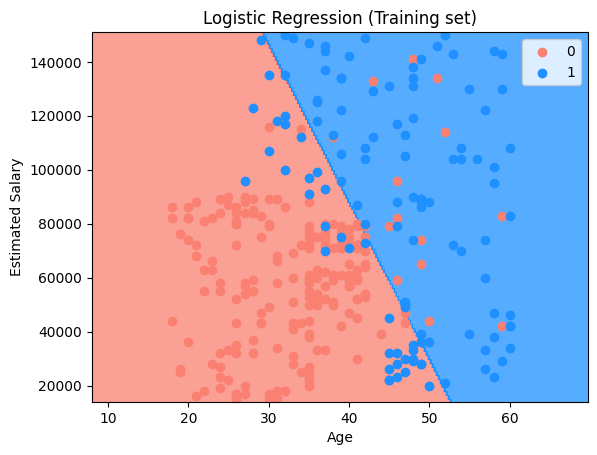

In [ ]:
from matplotlib.colors import ListedColormap
X_set, y_set = sc.inverse_transform(X_train), y_train
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 10, stop = X_set[:, 0].max() + 10, step = 0.25),
                     np.arange(start = X_set[:, 1].min() - 1000, stop = X_set[:, 1].max() + 1000, step = 0.25))
plt.contourf(X1, X2, classifier.predict(sc.transform(np.array([X1.ravel(), X2.ravel()]).T)).reshape(X1.shape),
             alpha = 0.75, cmap = ListedColormap(['#FA8072', '#1E90FF']))
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], c = ListedColormap(['#FA8072', '#1E90FF'])(i), label = j)
plt.title('Logistic Regression (Training set)')
plt.xlabel('Age')
plt.ylabel('Estimated Salary')
plt.legend()
plt.show()

## Visualising the Test set results

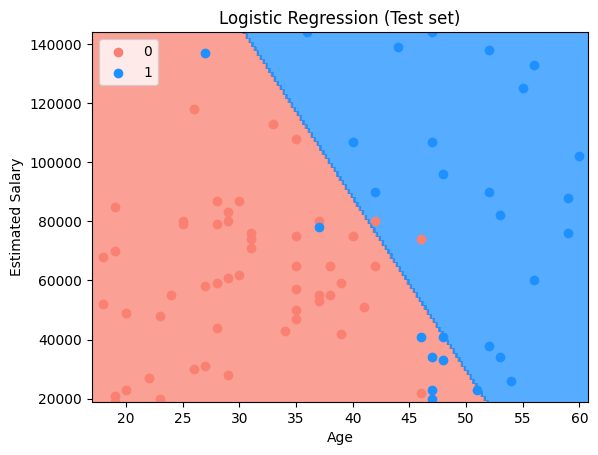

In [ ]:
from matplotlib.colors import ListedColormap
X_set, y_set = sc.inverse_transform(X_test), y_test
# Create a grid of points
X1, X2 = np.meshgrid(
    np.arange(start=X_set[:, 0].min() - 1, stop=X_set[:, 0].max() + 1, step=0.25),
    np.arange(start=X_set[:, 1].min() - 1, stop=X_set[:, 1].max() + 1, step=0.25)
)
# Predict for each point on the grid
Z = classifier.predict(sc.transform(np.array([X1.ravel(), X2.ravel()]).T)).reshape(X1.shape)
# Plot the decision boundary
plt.contourf(X1, X2, Z, alpha=0.75, cmap = ListedColormap(['#FA8072', '#1E90FF']) )
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())
# Define colors for scatter plot
colors = ['#FA8072', '#1E90FF']
# Plot the test set points
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(
        X_set[y_set == j, 0], X_set[y_set == j, 1],
        color=colors[i], label=j
    )
# Add titles and labels
plt.title('Logistic Regression (Test set)')
plt.xlabel('Age')
plt.ylabel('Estimated Salary')
plt.legend()
plt.show()